# Fit Modes Panel A/B Composite

This notebook rebuilds the merged fitting figure from the current standardized trajectory data. Edit the configuration cell to change colors, fonts, row titles, subplot titles, spacing, legend placement, figure size, and the OASIS Panel B target field (`OASIS SITReg` or `OASIS Greedy`).

Default output uses the current v001 standardized settings and saves PNG files only.

In [1]:
# Editable configuration
from pathlib import Path

SOURCE_VERSION = "v002_candidate"
OUTPUT_DIR = Path("experiments/paper_artifacts/fitting_figure/v002_candidate/panelAB_composite")
OUTPUT_FORMATS = ("png",)
OUTPUT_NAME_TEMPLATE = "fit_modes_panelAB_composite_{target_slug}"

# Change to ["OASIS Greedy"] to build the Greedy-target version, or include both values.
PANEL_B_OASIS_TARGETS = ["OASIS SITReg"]
PANEL_B_OASIS_TARGET_OPTIONS = ("OASIS SITReg", "OASIS Greedy")

DPI = 300
FIGSIZE = (7.9, 4.75)  # Existing generator used (7.9, 5.15); reduce height here by default.
SUBPLOTS_ADJUST = {
    "left": 0.095,
    "right": 0.995,
    "top": 0.88,
    "bottom": 0.22,
    "wspace": 0.38,
    "hspace": 1.00,  # Main control for spacing between Panel A and Panel B.
}

ROW_TITLES = {
    "A": "A. Similarity metric during unsupervised optimization",
    "B": "B. Target field fitting error during supervised fitting",
}
SUBPLOT_TITLES = {
    "OASIS rank-9": "OASIS M0136->F0173",
    "LungCT case01": "4DCT case01",
    "LungCT case08": "4DCT case 08",
}
X_LABEL = "Epoch"
Y_LABELS = {"A": "Similarity (1-NCC)", "B": "rRMSE (%)"}
SHOW_YLABEL_EVERY_PANEL = True

PANEL_A_YSCALE = "log"
PANEL_B_YSCALE = "log"
PANEL_A_YLIM = (1.0e-3, 5.0e-1)
PANEL_B_YLIM = (1.0e-1, 1.0e2)
PANEL_A_VALUE_FLOOR = 1.0e-12
X_LIM = (0, 2500)

FONT_SIZES = {
    "base": 8,
    "row_title": 12,
    "subplot_title": 9,
    "axis_label": 10,
    "tick": 7,
    "legend": 12,
}
ROW_TITLE_X = SUBPLOTS_ADJUST["left"]
ROW_TITLE_PAD = 0.055
SUBPLOT_TITLE_PAD = 4

LEGEND_BBOX = (0.5, 0.025)  # Main control for spacing between Panel B and the bottom legend.
LEGEND_NCOL = 4
LEGEND_FRAME = False

LINE_WIDTH = 1.7
GRID_COLOR = "#d8dce2"
GRID_LINEWIDTH = 0.5
GRID_ALPHA = 0.75
SMOOTH = True
PANEL_A_SMOOTH_WINDOWS = {
    "panelA_idir": 3,
    "panelA_sinr_cps4": 25,
    "panelA_direct_cp_cps4": 25,
    "panelA_direct_cp_multistage": 25,
}
PANEL_B_SMOOTH_WINDOWS = {
    "IDIR": 3,
    "SINR cps4": 25,
    "DirectCP cps4": 25,
    "DirectCP 8-4-2": 25,
    "DirectCP 4stage cps4": 25,
}

METHOD_STYLES = {
    "IDIR": {"color": "#2C7BB6", "linestyle": "-", "marker": None, "zorder": 5},
    "SINR cps4": {"color": "#F28E2B", "linestyle": "-", "marker": None, "zorder": 4},
    "DirectCP cps4": {"color": "#D62728", "linestyle": "-", "marker": None, "zorder": 3},
    "DirectCP 8-4-2": {"color": "#CC79A7", "linestyle": "-", "marker": None, "zorder": 2},
    "DirectCP 4stage cps4": {"color": "#CC79A7", "linestyle": "-", "marker": None, "zorder": 2},
}


In [2]:
# Imports and module loading
from __future__ import annotations

import importlib.util
import json
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "experiments/paper_artifacts/artifact_standard.json").exists():
            return candidate
    raise RuntimeError(f"Could not find repository root from {start}")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

MODULE_PATH = REPO_ROOT / "experiments/2026-06-26_fit_modes_paper_figure/fit_modes_method_comparison.py"
spec = importlib.util.spec_from_file_location("fit_modes_method_comparison", MODULE_PATH)
fm = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = fm
spec.loader.exec_module(fm)

OUTPUT_DIR = REPO_ROOT / OUTPUT_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_dir = OUTPUT_DIR / ".ipynb_checkpoints"
if checkpoint_dir.exists():
    shutil.rmtree(checkpoint_dir)


In [3]:
# Load standardized trajectories and target powers
standard = fm.load_standard()
nicknames = fm.load_nicknames()

panel_a_curves = fm.load_standardized_panelA_global_ncc_curves()
reference_field_curves = fm.load_relative_field_fit_curves(fm.selected_runs())
power_summary = fm.target_power_summary(reference_field_curves, fm.RELATIVE_FIELD_CASE_ORDER)
all_field_curves = fm.load_rrmse_lr_trajectory_curves()
field_curves = fm.filter_standardized_field_fit_curves(all_field_curves, standard)
power_by_case = fm._target_power_map(power_summary)

print(f"Loaded {len(panel_a_curves)} Panel A curves")
print(f"Loaded {len(field_curves)} standardized Panel B field-fit curves")
print("Panel B OASIS target options:", PANEL_B_OASIS_TARGET_OPTIONS)


Loaded 12 Panel A curves
Loaded 16 standardized Panel B field-fit curves
Panel B OASIS target options: ('OASIS SITReg', 'OASIS Greedy')


In [4]:
# Drawing helpers

def target_slug(target: str) -> str:
    return str(target).replace("OASIS ", "").lower().replace(" ", "_")


def method_style(method: str) -> dict:
    if method in METHOD_STYLES:
        return METHOD_STYLES[method]
    return fm.METHOD_STYLE[method]


def smooth_values(values: np.ndarray, window: int) -> np.ndarray:
    if not SMOOTH:
        return values
    return fm._smooth(values, int(window))


def panel_display_label(plot_method_id: str) -> str:
    return fm.artifact_display_name(plot_method_id, plot_method_id, nicknames)


def legend_handles() -> list[Line2D]:
    handles = []
    seen = set()
    for plot_method_id in fm.PANELA_PLOT_METHOD_ORDER:
        label = panel_display_label(plot_method_id)
        if label in seen:
            continue
        seen.add(label)
        style_method = fm.PANELA_STYLE_METHOD_BY_PLOT_ID[plot_method_id]
        style = method_style(style_method)
        handles.append(
            Line2D(
                [0],
                [0],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style.get("marker") or None,
                markersize=3,
                linewidth=max(LINE_WIDTH, 1.8),
                label=label,
            )
        )
    return handles


def draw_panelab(panelb_oasis_target: str) -> plt.Figure:
    if panelb_oasis_target not in PANEL_B_OASIS_TARGET_OPTIONS:
        valid = ", ".join(PANEL_B_OASIS_TARGET_OPTIONS)
        raise ValueError(f"Invalid Panel B OASIS target {panelb_oasis_target!r}; expected one of: {valid}")

    plt.rcParams.update(
        {
            "font.size": FONT_SIZES["base"],
            "axes.titlesize": FONT_SIZES["subplot_title"],
            "axes.labelsize": FONT_SIZES["axis_label"],
            "xtick.labelsize": FONT_SIZES["tick"],
            "ytick.labelsize": FONT_SIZES["tick"],
            "legend.fontsize": FONT_SIZES["legend"],
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.linewidth": 0.8,
        }
    )

    fig, axes = plt.subplots(
        2,
        len(fm.PANELA_CASE_ORDER),
        figsize=FIGSIZE,
        sharex=True,
        sharey="row",
        constrained_layout=False,
    )
    axes = np.asarray(axes)
    fig.subplots_adjust(**SUBPLOTS_ADJUST)

    for col, case in enumerate(fm.PANELA_CASE_ORDER):
        ax = axes[0, col]
        for plot_method_id in fm.PANELA_PLOT_METHOD_ORDER:
            matches = [
                curve
                for curve in panel_a_curves
                if curve.case == case and curve.plot_method_id == plot_method_id
            ]
            if not matches:
                continue
            curve = matches[0]
            style_method = fm.PANELA_STYLE_METHOD_BY_PLOT_ID[plot_method_id]
            style = method_style(style_method)
            values = np.maximum(1.0 + curve.values, PANEL_A_VALUE_FLOOR)
            values = smooth_values(values, PANEL_A_SMOOTH_WINDOWS.get(plot_method_id, 25))
            ax.plot(
                curve.epochs,
                values,
                color=style["color"],
                linestyle=style["linestyle"],
                linewidth=LINE_WIDTH,
                marker=style.get("marker") or None,
                markersize=2.0,
                markevery=max(1, len(curve.epochs) // 8) if style.get("marker") else None,
                zorder=style["zorder"],
                label=panel_display_label(plot_method_id),
            )
        ax.set_title(SUBPLOT_TITLES.get(case, case), fontsize=FONT_SIZES["subplot_title"], pad=SUBPLOT_TITLE_PAD)
        ax.set_yscale(PANEL_A_YSCALE)
        ax.set_ylim(*PANEL_A_YLIM)
        ax.set_xlim(*X_LIM)
        ax.tick_params(axis="both", labelsize=FONT_SIZES["tick"])
        ax.tick_params(axis="x", labelbottom=True)
        ax.tick_params(axis="y", labelleft=True)
        ax.set_xlabel(X_LABEL, fontsize=FONT_SIZES["axis_label"])
        if SHOW_YLABEL_EVERY_PANEL or col == 0:
            ax.set_ylabel(Y_LABELS["A"], fontsize=FONT_SIZES["axis_label"])
        ax.grid(True, which="both", color=GRID_COLOR, linewidth=GRID_LINEWIDTH, alpha=GRID_ALPHA)

        field_case = fm._merged_panelb_case_for_panela_case(case, panelb_oasis_target)
        ax = axes[1, col]
        plotted = False
        for method in fm.STANDARDIZED_FIELD_FIT_METHOD_ORDER:
            matches = [curve for curve in field_curves if curve.case == field_case and curve.method == method]
            if not matches:
                continue
            curve = matches[0]
            style = method_style(method)
            values = fm._relative_rrmse_percent_values(curve, power_by_case[field_case])
            values = smooth_values(values, PANEL_B_SMOOTH_WINDOWS.get(method, 25))
            ax.plot(
                curve.epochs,
                values,
                color=style["color"],
                linestyle=style["linestyle"],
                linewidth=LINE_WIDTH,
                marker=style.get("marker") or None,
                markersize=2.0,
                markevery=max(1, len(curve.epochs) // 8) if style.get("marker") else None,
                zorder=style["zorder"],
                label=fm._display_method(method, nicknames),
            )
            plotted = True
        if not plotted:
            ax.text(
                0.5,
                0.5,
                "not run",
                transform=ax.transAxes,
                ha="center",
                va="center",
                color="#6f747c",
                fontsize=FONT_SIZES["base"],
            )
        ax.set_title(SUBPLOT_TITLES.get(case, case), fontsize=FONT_SIZES["subplot_title"], pad=SUBPLOT_TITLE_PAD)
        ax.set_yscale(PANEL_B_YSCALE)
        ax.set_ylim(*PANEL_B_YLIM)
        ax.set_xlim(*X_LIM)
        ax.tick_params(axis="both", labelsize=FONT_SIZES["tick"])
        ax.tick_params(axis="y", labelleft=True)
        ax.set_xlabel(X_LABEL, fontsize=FONT_SIZES["axis_label"])
        if SHOW_YLABEL_EVERY_PANEL or col == 0:
            ax.set_ylabel(Y_LABELS["B"], fontsize=FONT_SIZES["axis_label"])
        ax.grid(True, which="both", color=GRID_COLOR, linewidth=GRID_LINEWIDTH, alpha=GRID_ALPHA)

    for row_index, panel_key in [(0, "A"), (1, "B")]:
        bbox = axes[row_index, 0].get_position()
        fig.text(
            ROW_TITLE_X,
            min(bbox.y1 + ROW_TITLE_PAD, 0.995),
            ROW_TITLES[panel_key],
            ha="left",
            va="bottom",
            fontsize=FONT_SIZES["row_title"],
            fontweight="bold",
        )

    fig.legend(
        handles=legend_handles(),
        loc="lower center",
        bbox_to_anchor=LEGEND_BBOX,
        ncol=LEGEND_NCOL,
        frameon=LEGEND_FRAME,
        fontsize=FONT_SIZES["legend"],
    )
    return fig


Wrote manifest: experiments/paper_artifacts/fitting_figure/v002_candidate/panelAB_composite/fit_modes_panelAB_composite_manifest.json
Panel B OASIS target: OASIS SITReg
  png: experiments/paper_artifacts/fitting_figure/v002_candidate/panelAB_composite/fit_modes_panelAB_composite_sitreg.png


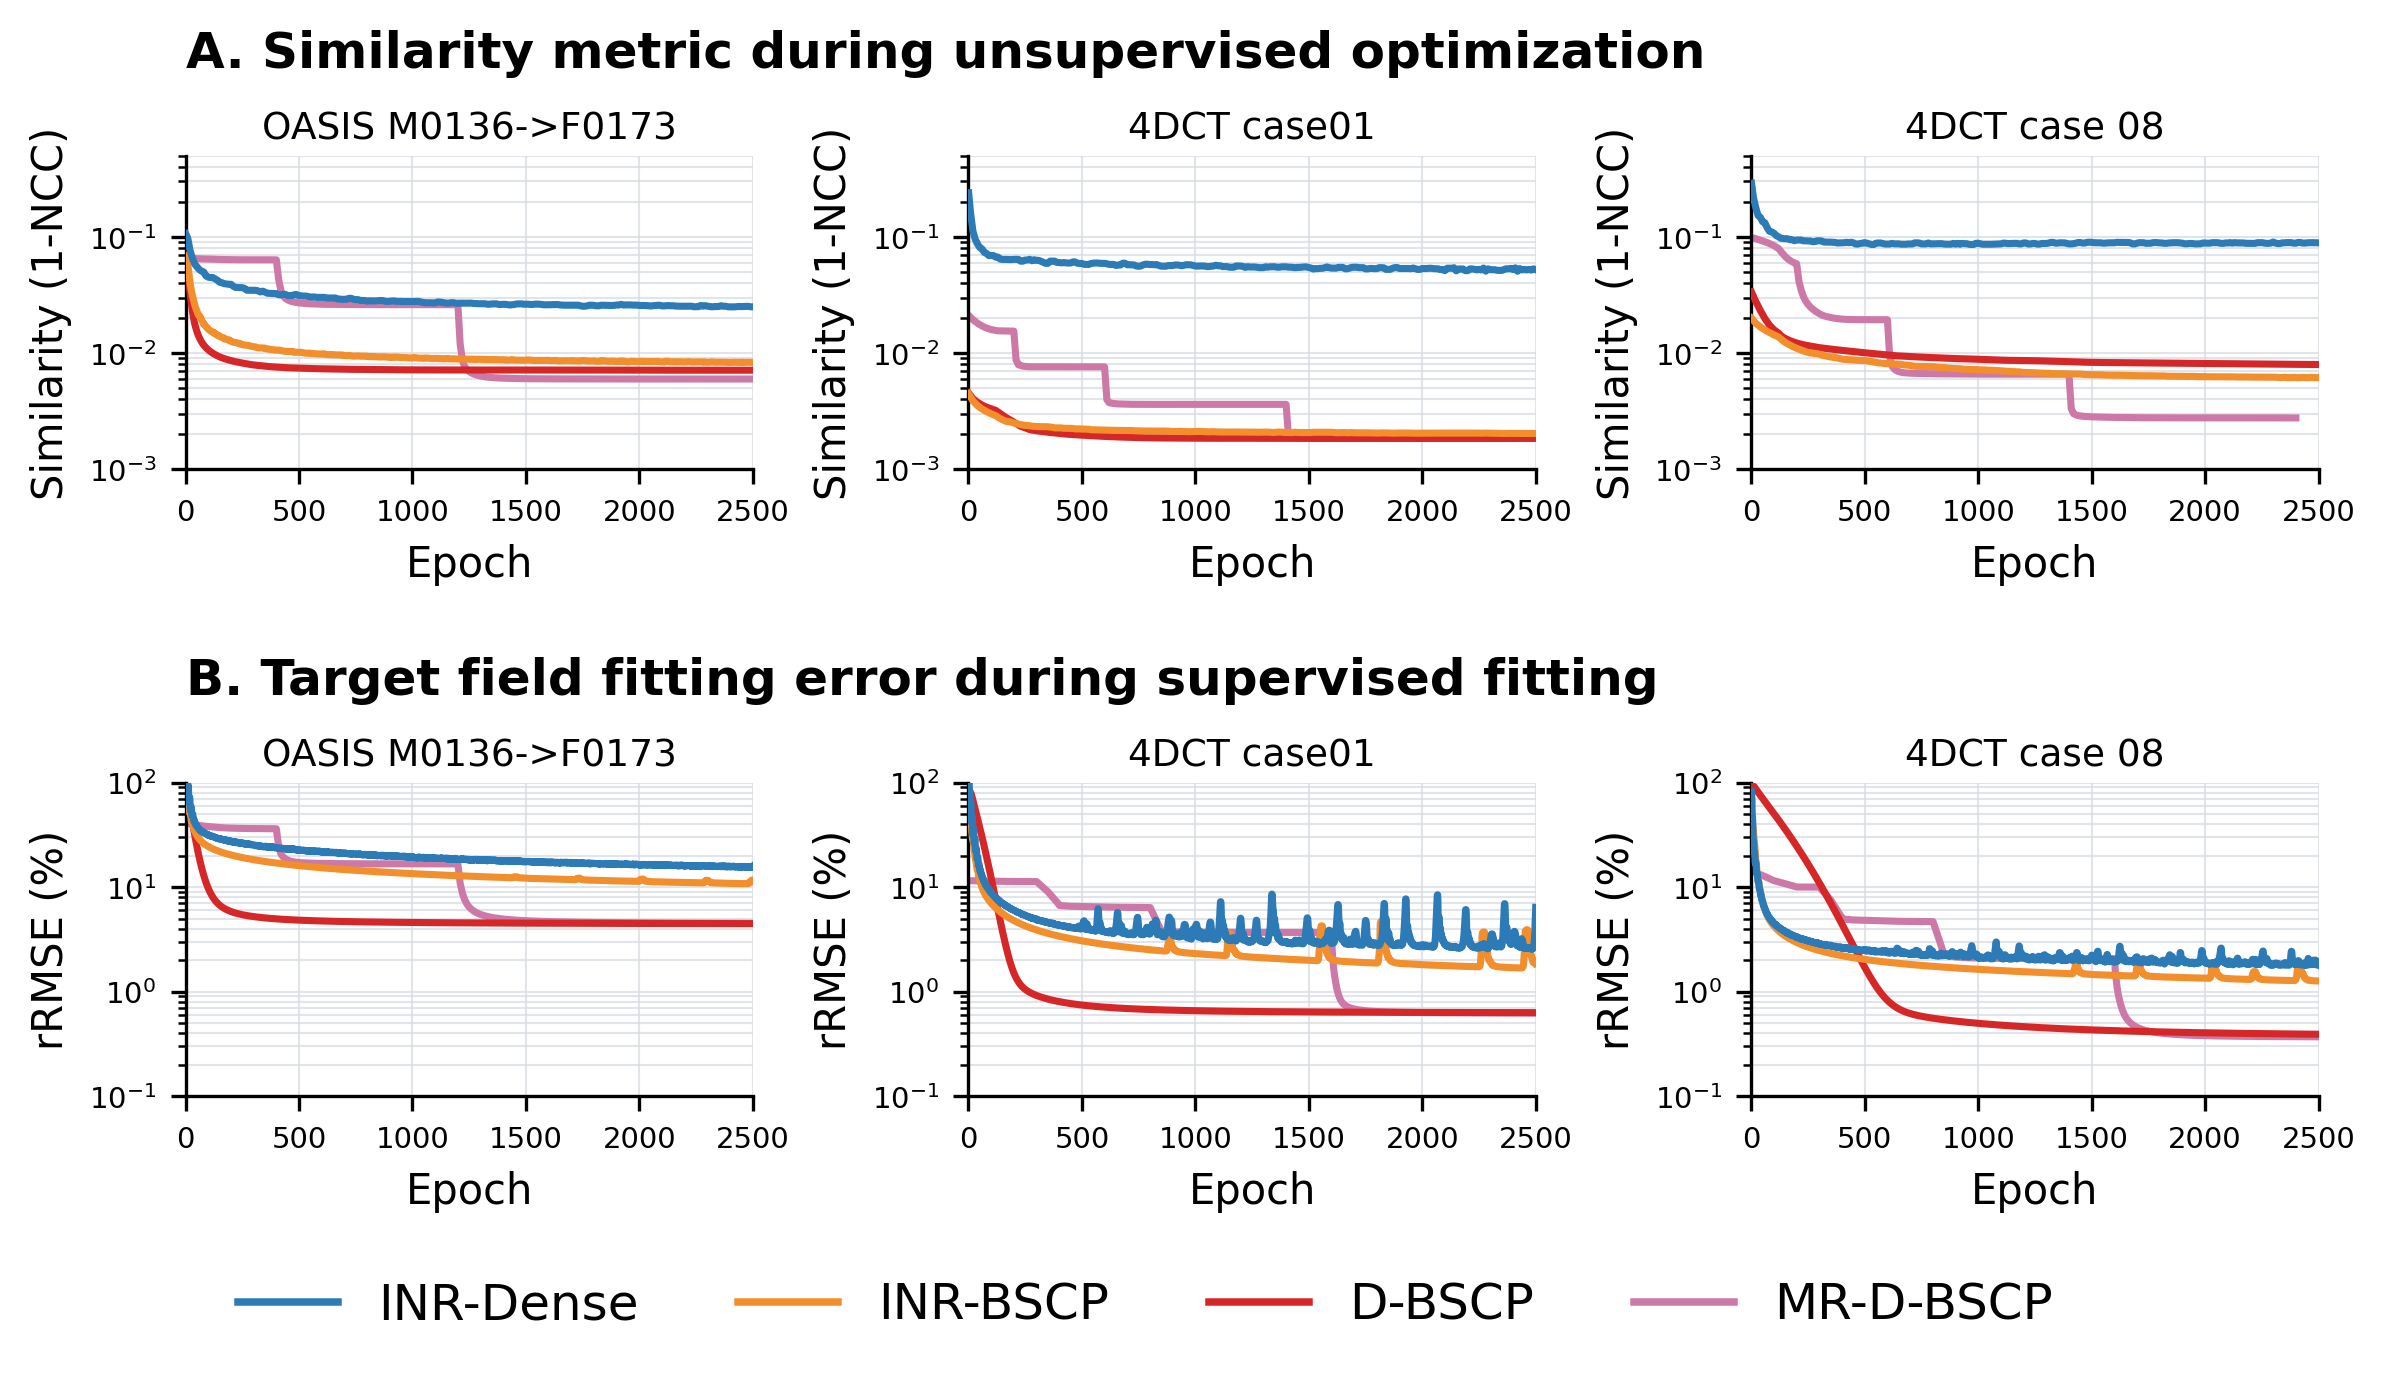

In [5]:
# Build, save, display, and record outputs
outputs = []
for target in PANEL_B_OASIS_TARGETS:
    fig = draw_panelab(target)
    stem = OUTPUT_NAME_TEMPLATE.format(target_slug=target_slug(target))
    saved = {}
    for fmt in OUTPUT_FORMATS:
        path = OUTPUT_DIR / f"{stem}.{fmt}"
        fig.savefig(path, dpi=DPI, bbox_inches="tight")
        saved[fmt] = path
    plt.close(fig)
    outputs.append({"panel_b_oasis_target": target, "files": {fmt: str(path) for fmt, path in saved.items()}})

manifest = {
    "artifact": "fit_modes_panelAB_composite_notebook",
    "source_version": SOURCE_VERSION,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebook": str((OUTPUT_DIR / "fit_modes_panelAB_composite.ipynb").relative_to(REPO_ROOT)),
    "source_files": {
        "standard": "experiments/paper_artifacts/artifact_standard.json",
        "nicknames": "experiments/paper_artifacts/method_nicknames.csv",
        "generator_module": "experiments/2026-06-26_fit_modes_paper_figure/fit_modes_method_comparison.py",
    },
    "metrics": {
        "panel_a": "1 - NCC = 1 + global_ncc_loss, plotted on a log scale",
        "panel_b": "rRMSE (%) = 100 * sqrt(mse / (target_power + 1e-12)), plotted on a log scale",
    },
    "panel_b_oasis_targets": PANEL_B_OASIS_TARGETS,
    "row_titles": ROW_TITLES,
    "subplot_titles": SUBPLOT_TITLES,
    "labels": {"x": X_LABEL, "y": Y_LABELS},
    "style_config": {
        "figsize": FIGSIZE,
        "dpi": DPI,
        "subplots_adjust": SUBPLOTS_ADJUST,
        "legend_bbox": LEGEND_BBOX,
        "font_sizes": FONT_SIZES,
        "method_styles": METHOD_STYLES,
        "line_width": LINE_WIDTH,
        "show_ylabel_every_panel": SHOW_YLABEL_EVERY_PANEL,
    },
    "outputs": outputs,
    "panel_a_curve_sources": sorted({curve.source for curve in panel_a_curves}),
    "panel_b_curve_sources": sorted({curve.source for curve in field_curves}),
}
manifest = fm.sanitize_public_value(manifest)
manifest_path = OUTPUT_DIR / "fit_modes_panelAB_composite_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2, sort_keys=True) + "\n")

print(f"Wrote manifest: {manifest_path.relative_to(REPO_ROOT)}")
for item in outputs:
    print(f"Panel B OASIS target: {item['panel_b_oasis_target']}")
    for fmt, filename in item["files"].items():
        rel = Path(filename).relative_to(REPO_ROOT)
        print(f"  {fmt}: {rel}")
        display(Image(filename=str(Path(filename))))
